## Homework Reflection: Weeks 1–4
### Victor Vasquez Gil | Boston University
This notebook brings together my written reflections, code, and results for all eight questions. I used airport examples for fixed effects and differences-in-differences because they connect the methods to my airline background. Those examples are hypothetical; the Pareto samples are simulated.

Data source: Joshua von Korff's DX702-mod-6 repository. The code loads the course CSVs directly from GitHub, so local copies are not needed.

In [19]:
from io import BytesIO
from urllib.request import urlopen
from urllib.error import URLError
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression

FIG_DIR = Path('reflection_figures')
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

GITHUB_BASE = (
    "https://raw.githubusercontent.com/"
    "joshua-vonkorff/DX702-mod-6/main/"
)
_csv_cache = {}

def load_csv(stem):
    """Read a course CSV directly from GitHub; reuse it during this session."""
    filename = stem if stem.endswith(".csv") else f"{stem}.csv"

    if filename not in _csv_cache:
        url = GITHUB_BASE + filename
        try:
            with urlopen(url, timeout=30) as response:
                data = response.read()
        except (URLError, TimeoutError) as exc:
            raise RuntimeError(
                f"Could not download {url}. Check your internet connection "
                "and whether the file is still available in the repository."
            ) from exc

        _csv_cache[filename] = pd.read_csv(BytesIO(data))
        print(f"Loaded {filename} from GitHub: {len(_csv_cache[filename]):,} rows")

    return _csv_cache[filename].copy()

def ols_hc1(y, design, names):
    # OLS with heteroskedasticity-robust HC1 standard errors.
    y, design = np.asarray(y, float), np.asarray(design, float)
    n, k = design.shape
    if np.linalg.matrix_rank(design) < k:
        raise ValueError('Design matrix is not full rank.')
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residual = y - design @ beta
    bread = np.linalg.inv(design.T @ design)
    meat = design.T @ (design * residual[:, None]**2)
    covariance = bread @ meat @ bread * n/(n-k)
    se = np.sqrt(np.diag(covariance))
    p = 2*stats.norm.sf(np.abs(beta/se))
    return pd.DataFrame({'coefficient': beta, 'robust_SE': se,
                         'p_value': p, 'CI_low': beta-1.96*se,
                         'CI_high': beta+1.96*se}, index=names)

## Week 1
### Question 1: Is the farthest match too far to be meaningful?

The farthest match has a distance of 0.210217 in Z. To me, being the closest available match does not automatically make it a good one. The control group only goes up to about 0.778, while the treated group goes up to about 0.988. Some treated observations are outside the control group's range, so I would be careful about treating those matches as similar. The farthest distance is also slightly above the 0.2 radius used in the other quiz approach, although that cutoff alone does not tell us whether the match is meaningful.

I would look at the distribution of Z in both groups and check how much the results change when I remove the more distant matches. With a maximum distance of 0.2, two of the 48 treated observations are excluded, and the estimated effect changes from 0.54336 to 0.53632. That is a small change, but I would still want to know what a difference of 0.2 means for the variable being measured. I would choose the distance limit based on that meaning, rather than which result I prefer. Removing observations also means the estimate represents a smaller group, and matching on Z does not account for other differences we have not measured.

In [23]:
matching = load_csv('homework_1.2')
treated = matching.loc[matching.X == 1].copy()
control = matching.loc[matching.X == 0].copy()
nn = NearestNeighbors(n_neighbors=1).fit(control[['Z']])
distances, indices = nn.kneighbors(treated[['Z']])
distances = distances.ravel()
nearest_control = control.iloc[indices.ravel()].copy()
nearest_effect = treated.Y.mean() - nearest_control.Y.mean()
pooled_sd = np.sqrt((treated.Z.var(ddof=1) + control.Z.var(ddof=1))/2)
before_smd = (treated.Z.mean()-control.Z.mean())/pooled_sd
after_smd = (treated.Z.mean()-nearest_control.Z.mean())/pooled_sd
keep = distances <= 0.2
caliper_effect = (
    (treated.Y.to_numpy()[keep] - nearest_control.Y.to_numpy()[keep]).mean()
    if keep.any() else np.nan
)
print(f'Farthest match: {distances.max():.6f}')
print(f'Nearest-neighbor effect (treated minus control): {nearest_effect:.5f}')
print(f'Z standardized mean difference: {before_smd:.3f} before; {after_smd:.3f} after')
print(f'Control Z range: {control.Z.min():.3f} to {control.Z.max():.3f}')
print(f'Treated Z range: {treated.Z.min():.3f} to {treated.Z.max():.3f}')
print(f'Treated observations above control maximum: {(treated.Z > control.Z.max()).sum()}')
print(f'0.2 caliper: retained {keep.sum()}/{len(keep)} treated; effect {caliper_effect:.5f}')

Farthest match: 0.210217
Nearest-neighbor effect (treated minus control): 0.54336
Z standardized mean difference: 1.170 before; 0.173 after
Control Z range: 0.005 to 0.778
Treated Z range: 0.120 to 0.988
Treated observations above control maximum: 18
0.2 caliper: retained 46/48 treated; effect 0.53632


### Question 2: My matching approach

I would match each treated observation with up to three of the closest controls, as long as each control is within 0.2 in Z. If only one or two controls are close enough, I would use those. If none are close enough, I would leave that treated observation out and report it. Then I would average the selected controls' outcomes, subtract that average from the treated observation's outcome, and average those differences across the treated observations that remain. A control could be used more than once, but each treated observation would receive the same weight.
I like this approach because it gives me more than one comparison when enough similar controls are available, while still putting a limit on how far away a match can be. In this dataset, it keeps 46 of the 48 treated observations and gives an estimated effect of 0.54557. The limitation is that the result only applies to the treated observations I could match, and using a small number of controls can make the estimate less precise. I would choose the matching rules before looking at the outcomes.


## Week 2

### Question 1: An example that would use fixed effects

With my airline background, an example that makes sense to me is looking at whether adding staff reduces passenger wait times at different airport stations. I would collect monthly staffing levels and average wait times. Some stations have more counter space or a better terminal layout, and those differences could affect wait times even if staffing stayed the same. Station fixed effects would account for those stable differences, while month fixed effects would account for shared changes, such as the holiday travel season.

The model would be **wait time = station effect + month effect + β × staffing + error**. The staffing coefficient would be the same across stations, and I would estimate it using changes within each station after accounting for the month effects. One issue is that stations might add staff because they already expect more passengers and longer lines. That changing demand could still affect the results, so fixed effects alone would not prove that staffing caused the change in wait times.



In [24]:
knn = NearestNeighbors(n_neighbors=3).fit(control[['Z']])
kd, ki = knn.kneighbors(treated[['Z']])
custom_effects, neighbor_counts = [], []
for row, y in enumerate(treated.Y):
    eligible = ki[row][kd[row] <= 0.2]
    if len(eligible):
        custom_effects.append(y - control.iloc[eligible].Y.mean())
        neighbor_counts.append(len(eligible))
custom_effect = np.mean(custom_effects)
print(f'Retained {len(custom_effects)}/{len(treated)} treated observations')
print(f'Controls per retained observation: {min(neighbor_counts)} to {max(neighbor_counts)}')
print(f'Custom matching effect: {custom_effect:.5f}')

# Reproduce the quiz radius estimate; each treated group receives equal weight.
radius_indices = nn.radius_neighbors(treated[['Z']], radius=0.2, return_distance=False)
radius_effects = [y-control.iloc[j].Y.mean() for y, j in zip(treated.Y, radius_indices) if len(j)]
all_controls = np.concatenate([j for j in radius_indices if len(j)])
print(f'Radius matching effect: {np.mean(radius_effects):.4f}')
print(f'Repeated control appearances after first use: {len(all_controls)-len(np.unique(all_controls))}')
quiz_radius_effect = treated.Y.mean() - np.mean([control.iloc[j].Y.mean() for j in radius_indices if len(j)])
print(f'Quiz convention (all treated, available control groups): {quiz_radius_effect:.4f}')
print('The quiz value uses all 48 treated outcomes but only 46 nonempty control groups.')
print('The matched-population radius estimate above uses the same 46 treated units on both sides.')

Retained 46/48 treated observations
Controls per retained observation: 1 to 3
Custom matching effect: 0.54557
Radius matching effect: 0.5689
Repeated control appearances after first use: 685
Quiz convention (all treated, available control groups): 0.5844
The quiz value uses all 48 treated outcomes but only 46 nonempty control groups.
The matched-population radius estimate above uses the same 46 treated units on both sides.


## Week 2
### Question 1: An example that would use fixed effects
With my airline background, an example that makes sense to me is looking at whether adding staff reduces passenger wait times at different airport stations. I would collect monthly staffing levels and average wait times. Some stations have more counter space or a better terminal layout, and those differences could affect wait times even if staffing stayed the same. Station fixed effects would account for those stable differences, while month fixed effects would account for shared changes, such as the holiday travel season.
The model would be wait time = station effect + month effect + β × staffing + error. The staffing coefficient would be the same across stations, and I would estimate it using changes within each station after accounting for the month effects. One issue is that stations might add staff because they already expect more passengers and longer lines. That changing demand could still affect the results, so fixed effects alone would not prove that staffing caused the change in wait times. The code below is a separate demonstration using the supplied quiz data: it fits group intercepts and a shared time trend, rather than the station and month effects in my airport example.

In [25]:
fixed = load_csv('homework_2.1')
long = fixed.melt(id_vars='time', var_name='group', value_name='outcome')
group_dummies = pd.get_dummies(long.group, dtype=float)
design = np.column_stack([group_dummies[['G1','G2','G3']], long.time])
fixed_result = ols_hc1(long.outcome, design, ['G1 intercept','G2 intercept','G3 intercept','common time slope'])
print(fixed_result.round(6).to_string())

Loaded homework_2.1.csv from GitHub: 100 rows
                   coefficient  robust_SE   p_value    CI_low   CI_high
G1 intercept          0.078552   0.075158  0.295953 -0.068759  0.225863
G2 intercept          0.589654   0.074024  0.000000  0.444567  0.734742
G3 intercept          0.269032   0.066037  0.000046  0.139598  0.398465
common time slope     0.009017   0.001041  0.000000  0.006978  0.011057


## Week 2
### Question 2: Bootstrapping the mean of a Pareto distribution
I used a Pareto distribution with a shape of 3 and a minimum value of 1. I tested sample sizes of 100, 500, 2,000, and 10,000. For each size, I generated 20 original samples and took 1,000 bootstrap samples from each one, with replacement. Each bootstrap sample was the same size as its original sample. I calculated the mean of each bootstrap sample, found the variance of those means, and averaged the variance estimates across the 20 original samples. Adding 1 to NumPy's Pareto output gives the version of the distribution with a minimum of 1.
The variance gets smaller as the sample size increases. For the distribution I used, the population variance is 0.75, so the variance of the mean is 0.75 / n. A larger sample gives a more stable average, although the occasional large Pareto value can still move the results around. This depends on the shape parameter: when 1 < shape ≤ 2, the mean exists but the population variance is infinite. A finite variance from a bootstrap run would not mean the population has a finite variance. My conclusion here also assumes that the bootstrap sample size increases with the original sample size.

In [26]:
rng_pareto = np.random.default_rng(42)
rng_mc = np.random.default_rng(43)
alpha, xm = 3.0, 1.0
population_variance = alpha*xm**2 / ((alpha-1)**2*(alpha-2))
B, repetitions, monte_carlo = 1000, 20, 3000
pareto_rows = []
for n in [100, 500, 2000, 10000]:
    bootstrap_variances = []
    for repetition in range(repetitions):
        sample = xm*(1 + rng_pareto.pareto(alpha, size=n))
        means = []
        # Batches cap memory use, especially for n=10,000.
        for start in range(0, B, 100):
            size = min(100, B-start)
            means.extend(rng_pareto.choice(sample, size=(size,n), replace=True).mean(axis=1))
        bootstrap_variances.append(np.var(means, ddof=1))
    independent_means = []
    for start in range(0, monte_carlo, 100):
        size = min(100, monte_carlo-start)
        draws = xm*(1 + rng_mc.pareto(alpha, size=(size,n)))
        independent_means.extend(draws.mean(axis=1))
    pareto_rows.append({'n':n, 'mean_bootstrap_variance':np.mean(bootstrap_variances),
                       'independent_sampling_variance':np.var(independent_means, ddof=1),
                       'theoretical_variance':population_variance/n})
pareto_results = pd.DataFrame(pareto_rows)
print(pareto_results.to_string(index=False, float_format=lambda x:f'{x:.7f}'))

    n  mean_bootstrap_variance  independent_sampling_variance  theoretical_variance
  100                0.0081872                      0.0071951             0.0075000
  500                0.0011727                      0.0014509             0.0015000
 2000                0.0003471                      0.0003792             0.0003750
10000                0.0000699                      0.0000748             0.0000750


## Week 3
#### Question 1: Testing for a change in the second derivative
To test this, I would add a squared time term and allow its coefficient to change after the event. The slope tells me how quickly the outcome changes, while the second derivative tells me whether that slope is itself changing. Using the quiz's event time of 50, I would define t = time - 50 and let D equal 1 at or after the event and 0 before it. The model would be Y = b₀ + b₁t + b₂t² + d₀D + d₁Dt + d₂Dt² + error. The second derivative is 2b₂ before the event and 2(b₂ + d₂) after it, so the change is 2d₂. I would test the null hypothesis that d₂ = 0.
I would keep the terms for changes in the level and slope, because otherwise the squared term might pick up those changes instead. The notebook checks all three outcome series at time 50. It also reproduces the original quiz comparison: value3 has the strongest level discontinuity, and value1 has the strongest slope discontinuity. Those findings do not automatically mean there is a change in curvature. For time-series data, I would also check whether nearby observations have related errors and use a method such as HAC standard errors or a block bootstrap if needed. This compares curvature on either side of the event; a derivative at the exact point of a jump may not exist.
For the curvature change tests below, the p-values are about 0.979, 0.176, and 0.765 for value1, value2, and value3. All are above 0.05, so these tests do not give me enough evidence to conclude that the curvature changed. That is different from proving there was no change, and the reported HC1 results do not adjust for serial correlation.

In [27]:
event = load_csv('homework_3.1')
event_time = 50  # Confirmed by the supplied Week 3 coding quiz.
t = event.time.to_numpy() - event_time
post = (t >= 0).astype(int)
event_design = np.column_stack([np.ones(len(t)), t, t**2, post, post*t, post*t**2])
event_rows = []
for outcome in ['value1','value2','value3']:
    result = ols_hc1(event[outcome], event_design,
                     ['intercept','time','time_squared','post','post_time','post_time_squared'])
    r = result.loc['post_time_squared']
    event_rows.append({'outcome':outcome, 'curvature_change':2*r.coefficient,
                       'CI_low':2*r.CI_low, 'CI_high':2*r.CI_high, 'p_value':r.p_value})
event_results = pd.DataFrame(event_rows)
print('Confirmed event time: 50; HC1 normal-approximation inference')
print(event_results.round(6).to_string(index=False))

Loaded homework_3.1.csv from GitHub: 100 rows
Confirmed event time: 50; HC1 normal-approximation inference
outcome  curvature_change    CI_low  CI_high  p_value
 value1          0.000054 -0.003986 0.004094 0.979183
 value2          0.003193 -0.001430 0.007815 0.175859
 value3         -0.000589 -0.004441 0.003264 0.764641


### Question 2: My differences-in-differences example

Suppose one airport station adds self-service bag-drop kiosks and a similar station continues operating as before. At the station with kiosks, the average wait falls from **20 minutes to 12 minutes**. At the comparison station, it falls from **15 minutes to 13 minutes**. I made up these numbers for the example. Looking only at the kiosk station would suggest an eight-minute improvement, but the comparison station also improved by two minutes without adding kiosks.

| Station | Before | After | Change |
| --- | --- | --- | --- |
| Added kiosks | 20 minutes | 12 minutes | −8 minutes |
| Comparison station | 15 minutes | 13 minutes | −2 minutes |

The differences-in-differences estimate is **(12 − 20) − (13 − 15) = −6 minutes**. There is a nonzero estimated effect: the kiosk station's wait time fell by six minutes more than the comparison station's. To interpret that as the effect of the kiosks, I would need to assume the stations would have followed parallel trends without them. I would also check whether staffing, passenger volume, or another change affected only one station, and whether the kiosks affected the comparison station. These four averages are enough to show the calculation, but they do not establish statistical significance or let me verify parallel trends.


 treated  post  wait_minutes
       0     0            15
       0     1            13
       1     0            20
       1     1            12
Difference-in-differences: -6.0 minutes
Regression treatment × post coefficient: -6.0


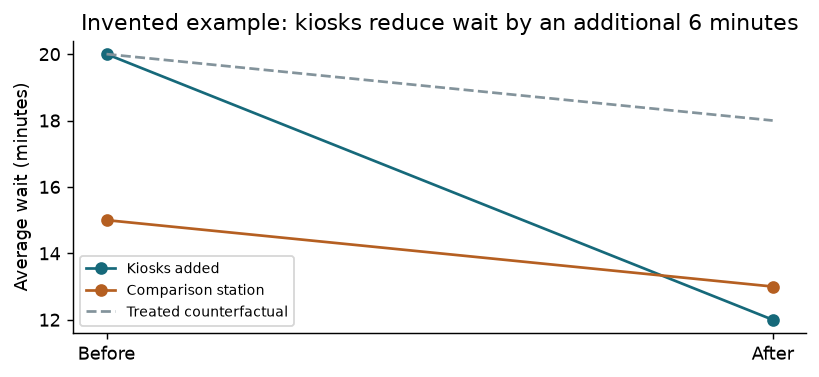

In [28]:
did = pd.DataFrame({'treated':[0,0,1,1], 'post':[0,1,0,1],
                    'wait_minutes':[15,13,20,12]})
means = did.pivot(index='treated', columns='post', values='wait_minutes')
did_effect = (means.loc[1,1]-means.loc[1,0])-(means.loc[0,1]-means.loc[0,0])
did_design = np.column_stack([np.ones(4), did.treated, did.post, did.treated*did.post])
did_coefficients = np.linalg.lstsq(did_design, did.wait_minutes, rcond=None)[0]
print(did.to_string(index=False))
print(f'Difference-in-differences: {did_effect:.1f} minutes')
print(f'Regression treatment × post coefficient: {did_coefficients[-1]:.1f}')
fig, ax = plt.subplots(figsize=(6.4,3))
ax.plot([0,1], [20,12], 'o-', color='#16697a', label='Kiosks added')
ax.plot([0,1], [15,13], 'o-', color='#b55f21', label='Comparison station')
ax.plot([0,1], [20,18], '--', color='#83939b', label='Treated counterfactual')
ax.set(xticks=[0,1], xticklabels=['Before','After'], ylabel='Average wait (minutes)',
       title='Invented example: kiosks reduce wait by an additional 6 minutes')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG_DIR/'did.png', dpi=180); plt.show()

### Additional Week 3 quiz checks
These checks use the original linear event study model and the supplied DiD datasets. They are separate from the invented kiosk example above. Conventional OLS standard errors match the method requested in the quiz.

In [29]:
def ols_conventional(y, design, names):
    y, design = np.asarray(y, float), np.asarray(design, float)
    n, k = design.shape
    beta = np.linalg.lstsq(design,y,rcond=None)[0]
    residual = y-design@beta
    covariance = np.linalg.inv(design.T@design)*(residual@residual)/(n-k)
    se = np.sqrt(np.diag(covariance))
    return pd.DataFrame({'coefficient':beta,'SE':se,'t':beta/se,
                         'p_value':2*stats.t.sf(np.abs(beta/se),df=n-k)},index=names)

linear_event_design = np.column_stack([np.ones(len(t)),t,post,t*post])
event_quiz_rows = []
for outcome in ['value1','value2','value3']:
    fit = ols_conventional(event[outcome],linear_event_design,['intercept','time','level_change','slope_change'])
    event_quiz_rows.append({'outcome':outcome,'level_change':fit.loc['level_change','coefficient'],
        'level_t':fit.loc['level_change','t'], 'slope_change':fit.loc['slope_change','coefficient'],
        'slope_t':fit.loc['slope_change','t']})
print(pd.DataFrame(event_quiz_rows).round(5).to_string(index=False))
did_quiz_rows = []
for suffix, number in [('a',1),('b',2)]:
    data = load_csv(f'homework_3.2.{suffix}')
    group, period, outcome = data[f'group{number}'], data[f'time{number}'], data[f'outcome{number}']
    design = np.column_stack([np.ones(len(data)),group,period,group*period])
    fit = ols_conventional(outcome,design,['intercept','group','post','treatment_effect'])
    effect = fit.loc['treatment_effect']
    did_quiz_rows.append({'dataset':f'Group {number}',**effect.to_dict()})
did_quiz_results = pd.DataFrame(did_quiz_rows)
print(did_quiz_results.round(6).to_string(index=False))
print('Group 2 estimate is about 1.350; 1.248 is the closest listed quiz answer, not the exact fit.')

outcome  level_change  level_t  slope_change  slope_t
 value1       0.90348  2.36249       0.10532  7.95126
 value2       0.70121  1.68848       0.03692  2.56673
 value3       1.79260  4.72422       0.05070  3.85713
Loaded homework_3.2.a.csv from GitHub: 1,000 rows
Loaded homework_3.2.b.csv from GitHub: 1,000 rows
dataset  coefficient       SE         t  p_value
Group 1     0.685847 0.062522 10.969611      0.0
Group 2     1.349859 0.147047  9.179774      0.0
Group 2 estimate is about 1.350; 1.248 is the closest listed quiz answer, not the exact fit.


## Week 4
### Question 1: Dividing W into multiple ranges
I divided W into ten ranges using quantiles, which gave me 500 observations per range. Within each range, I separated the observations with Z = 1 from those with Z = 0. I calculated the difference in their average Y values and divided it by the difference in their average X values. Then I averaged the ten ratios, as requested in the second quiz method. I used equal-count ranges because equal-width ranges left very few observations at the high end of W.
The average with ten equal-count ranges was 1.5089, close to the quiz answer of about 1.5. The biggest issue I found was the uneven number of observations when using equal-width ranges. With five equal-width ranges, the last one had only eight observations and an estimated effect of −1.9268, pulling the overall average down to 0.8159. With ten equal-width ranges, one did not contain both Z groups, so its ratio could not be calculated. The equal-width results in the table average only the valid ranges. That showed me why I needed to look at the counts behind each estimate.
There is still a tradeoff. More ranges give narrower comparisons but fewer observations in each, and equal-count ranges can be wide near the ends of the distribution. A very small difference in average X also makes the ratio unstable. For a causal interpretation, Z needs to affect X without directly affecting Y, and it should be independent of other causes of Y after accounting for W. W should also not be affected by the instrument. Splitting the data into ranges does not prove those assumptions hold.

In [30]:
iv = load_csv('homework_4.1')
iv['W_bin'] = pd.qcut(iv.W, q=10, duplicates='drop')
rows = []
for interval, g in iv.groupby('W_bin', observed=True):
    g0, g1 = g[g.Z == 0], g[g.Z == 1]
    dx = g1.X.mean() - g0.X.mean()
    dy = g1.Y.mean() - g0.Y.mean()
    valid = len(g0) > 0 and len(g1) > 0 and abs(dx) > 1e-8
    rows.append({'W_range':str(interval), 'n':len(g),
                 'n_Z0':len(g0), 'n_Z1':len(g1),
                 'delta_X':dx, 'delta_Y':dy,
                 'IV_effect':dy/dx if valid else np.nan,
                 'sparse':min(len(g0), len(g1)) < 20})
iv_results = pd.DataFrame(rows)
print(iv_results.round(4).to_string(index=False))
if iv_results.IV_effect.isna().any():
    raise ValueError('At least one bin has an undefined ratio; revise the binning.')
mean_iv_effect = iv_results.IV_effect.mean()
print(f'Average of within-bin ratios (quiz approach 2): {mean_iv_effect:.4f}')
z_means = iv.groupby('Z')[['X','Y']].mean()
unconditional_iv = ((z_means.loc[1,'Y']-z_means.loc[0,'Y']) /
                    (z_means.loc[1,'X']-z_means.loc[0,'X']))
print(f'Unconditional ratio (quiz approach 1): {unconditional_iv:.4f}')

Loaded homework_4.1.csv from GitHub: 5,000 rows
          W_range   n  n_Z0  n_Z1  delta_X  delta_Y  IV_effect  sparse
 (-3.304, -1.277] 500   262   238   1.0440   1.6075     1.5397   False
 (-1.277, -0.855] 500   251   249   0.9861   1.2971     1.3153   False
 (-0.855, -0.547] 500   262   238   0.9824   1.5807     1.6090   False
 (-0.547, -0.277] 500   240   260   0.8807   1.4252     1.6182   False
(-0.277, -0.0322] 500   250   250   0.9992   1.4570     1.4583   False
 (-0.0322, 0.226] 500   258   242   1.0786   1.6590     1.5381   False
   (0.226, 0.491] 500   245   255   1.2374   1.9834     1.6029   False
   (0.491, 0.814] 500   252   248   0.9704   1.4414     1.4853   False
   (0.814, 1.303] 500   235   265   1.0414   1.5897     1.5266   False
   (1.303, 4.783] 500   238   262   0.9656   1.3475     1.3955   False
Average of within-bin ratios (quiz approach 2): 1.5089
Unconditional ratio (quiz approach 1): 1.5619


In [32]:
# Check the equal-width results discussed in the reflection.
# Keep every bin in the diagnostic table, including undefined ratios.
def summarize_iv_bins(frame, number_of_bins, method):
    if method == 'equal count':
        labels = pd.qcut(frame['W'], q=number_of_bins, duplicates='drop')
    elif method == 'equal width':
        labels = pd.cut(frame['W'], bins=number_of_bins, include_lowest=True)
    else:
        raise ValueError("Use 'equal count' or 'equal width'.")

    records = []
    for interval in labels.cat.categories:
        group = frame.loc[labels == interval]
        z0 = group.loc[group['Z'] == 0]
        z1 = group.loc[group['Z'] == 1]
        delta_x = z1['X'].mean() - z0['X'].mean()
        delta_y = z1['Y'].mean() - z0['Y'].mean()

        valid = len(z0) > 0 and len(z1) > 0 and abs(delta_x) > 1e-8
        records.append({
            'W_range': str(interval),
            'n': len(group),
            'n_Z0': len(z0),
            'n_Z1': len(z1),
            'delta_X': delta_x,
            'IV_effect': delta_y / delta_x if valid else np.nan,
            'valid_ratio': valid
        })
    return pd.DataFrame(records)

sensitivity_rows = []
for bins in [5, 10, 20]:
    for method in ['equal count', 'equal width']:
        bin_results = summarize_iv_bins(iv, bins, method)
        valid = bin_results['valid_ratio']
        sensitivity_rows.append({
            'method': method,
            'requested_bins': bins,
            'actual_bins': len(bin_results),
            'valid_bins': int(valid.sum()),
            'mean_ratio': bin_results.loc[valid, 'IV_effect'].mean()
        })

iv_sensitivity = pd.DataFrame(sensitivity_rows)
print('Sensitivity comparison: average of the valid within-bin ratios')
print(iv_sensitivity.round(4).to_string(index=False))

print('\nFive equal-width bins: inspect the sparse upper range')
equal_width_five = summarize_iv_bins(iv, 5, 'equal width')
print(equal_width_five.round(4).to_string(index=False))

print('\nTen equal-width bins: ranges without a defined ratio')
equal_width_ten = summarize_iv_bins(iv, 10, 'equal width')
print(equal_width_ten.loc[~equal_width_ten['valid_ratio']].to_string(index=False))
print('\nThe main ten-quantile-bin estimate uses all ten ranges.')
print('Sensitivity means exclude undefined ratios; valid-bin counts are shown explicitly.')

Sensitivity comparison: average of the valid within-bin ratios
     method  requested_bins  actual_bins  valid_bins  mean_ratio
equal count               5            5           5      1.5156
equal width               5            5           5      0.8159
equal count              10           10          10      1.5089
equal width              10           10           9      0.9085
equal count              20           20          20      1.5055
equal width              20           20          17      1.6166

Five equal-width bins: inspect the sparse upper range
          W_range    n  n_Z0  n_Z1  delta_X  IV_effect  valid_ratio
 (-3.312, -1.686]  194   104    90   0.9213     1.6162         True
(-1.686, -0.0687] 2225  1122  1103   0.9812     1.4950         True
 (-0.0687, 1.549] 2263  1115  1148   1.0654     1.5702         True
   (1.549, 3.166]  310   148   162   1.0248     1.3246         True
   (3.166, 4.783]    8     4     4  -0.1631    -1.9268         True

Ten equal-width bi

### Question 2: College outcomes and logistic regression near a score of 80

I used test scores from **75 to 85** and plotted both datasets. Putting every outcome at 0 or 1 would make it hard to see what was happening, so I grouped scores into **half-point bins** and plotted the percentage with `Y = 1` in each bin. I added **95% Wilson intervals** to show uncertainty around those observed percentages. I also made sure 80 fell on a bin boundary, so a bin would not combine students from both sides of the cutoff.

I compared those points with logistic regression using the score centered at 80, an indicator for being at or above 80, and an interaction between the two. This lets the model show a jump at the cutoff and a different slope afterward. I also plotted a model that used only the score. The score-only curve smooths over the jump, while the model with the cutoff follows the pattern more closely. Dataset B also shows the quiz's pattern: the outcome probability increases before 80 and has a flatter slope afterward. The plots below show this comparison.

| Dataset | Predicted probability just below 80 | Predicted probability at 80 | Estimated jump |
| --- | --- | --- | --- |
| A | 31.0% | 59.6% | 28.6 percentage points |
| B | 70.6% | 90.2% | 19.6 percentage points |

The change is easy to see in both datasets once the outcomes are shown as proportions. These percentages are the model's fitted probabilities at the cutoff, not the raw bin averages. I would also be careful about calling them a causal effect or a measure of test accuracy, since the model was fitted to the same data shown in the plot. To make a causal claim, I would need evidence that other important factors stay comparable around 80 and that students cannot precisely control which side of the cutoff they land on.

Loaded homework_4.2.a.csv from GitHub: 100,000 rows
Loaded homework_4.2.b.csv from GitHub: 100,000 rows


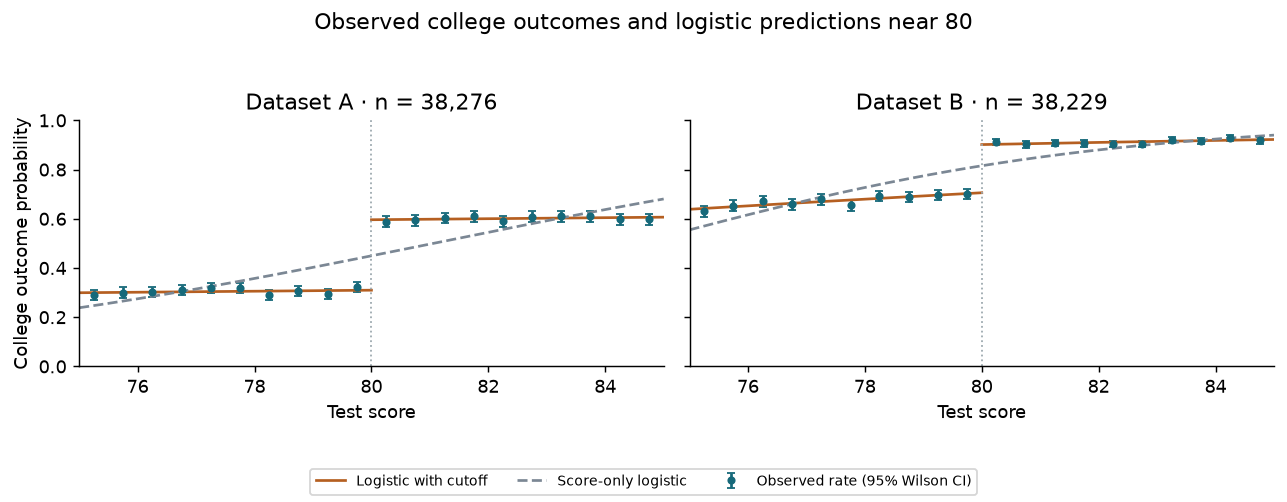

dataset     n  p_below_80  p_at_80   jump
      A 38276      0.3098   0.5961 0.2864
      B 38229      0.7058   0.9016 0.1958


In [33]:
def wilson_interval(successes, n, z=1.96):
    p = np.asarray(successes)/np.asarray(n)
    denominator = 1 + z*z/n
    center = (p+z*z/(2*n))/denominator
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/denominator
    return center-half, center+half

def logistic_features(x):
    centered = np.asarray(x)-80
    above = (np.asarray(x) >= 80).astype(float)
    return np.column_stack([centered, above, centered*above])

college_results = []
fig, axes = plt.subplots(1,2,figsize=(10,3.8),sharey=True)
for ax, suffix, xname, yname in zip(axes, ['a','b'], ['X','X2'], ['Y','Y2']):
    source = load_csv(f'homework_4.2.{suffix}')
    d = source.rename(columns={xname:'X',yname:'Y'})
    d = d.loc[d.X.between(75,85)].copy()
    # Large C makes the L2 penalty negligible for this descriptive fit.
    fit = LogisticRegression(C=1e10, max_iter=2000, tol=1e-10)
    fit.fit(logistic_features(d.X), d.Y)
    smooth = LogisticRegression(C=1e10, max_iter=2000, tol=1e-10)
    smooth.fit((d.X.to_numpy()-80).reshape(-1,1), d.Y)
    d['score_bin'] = pd.cut(d.X, np.arange(75,85.5,0.5), right=False)
    b = d.groupby('score_bin', observed=True).agg(score=('X','mean'),
        successes=('Y','sum'), n=('Y','size'), observed=('Y','mean'))
    low, high = wilson_interval(b.successes.to_numpy(), b.n.to_numpy())
    ax.errorbar(b.score, b.observed, yerr=[b.observed-low,high-b.observed],
                fmt='o', ms=3.5, capsize=2, color='#16697a', label='Observed rate (95% Wilson CI)')
    for j, grid in enumerate([np.linspace(75,80-1e-6,200),np.linspace(80,85,200)]):
        ax.plot(grid, fit.predict_proba(logistic_features(grid))[:,1], color='#b55f21',
                label='Logistic with cutoff' if j==0 else None)
    grid = np.linspace(75,85,400)
    ax.plot(grid, smooth.predict_proba((grid-80).reshape(-1,1))[:,1], '--',
            color='#7b8794', label='Score-only logistic')
    ax.axvline(80, color='#9da9af', linewidth=1, linestyle=':')
    ax.set(title=f'Dataset {suffix.upper()} · n = {len(d):,}', xlabel='Test score',
           xlim=(75,85), ylim=(0,1))
    cutoff_probs = fit.predict_proba(np.array([[0,0,0],[0,1,0]]))[:,1]
    college_results.append({'dataset':suffix.upper(),'n':len(d),
                            'p_below_80':cutoff_probs[0], 'p_at_80':cutoff_probs[1],
                            'jump':cutoff_probs[1]-cutoff_probs[0]})
axes[0].set_ylabel('College outcome probability')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8)
fig.suptitle('Observed college outcomes and logistic predictions near 80', fontsize=12)
fig.tight_layout(rect=(0,0.11,1,0.94))
fig.savefig(FIG_DIR/'college_outcome.png', dpi=200)
plt.show()
college_results = pd.DataFrame(college_results)
print(college_results.round(4).to_string(index=False))